# BÀI THỰC HÀNH TUẦN 6: PHÂN TÍCH PHÂN BIỆT TUYẾN TÍNH (LDA)
- **Họ và tên**: Nguyễn Hải Anh  
- **MSSV**: 24001968  
- **Học phần**: Machine Learning


## Ví dụ A.1: Xây dựng phương pháp LDA cho dữ liệu 2 lớp (Binary Labeled Data)
**Đề bài**: Trong ví dụ này chúng ta tạo 02 tập dữ liệu ngẫu nhiên 02 chiều với số điểm lần lượt là $N_1=50$ và $N_2=40$, phân bố chuẩn với hiệp phương sai và kỳ vọng khác nhau, ứng với 02 nhãn là 1 và 2.
- Hiển thị trực quan dữ liệu cũng như đánh dấu tâm điểm (vector trung bình) của mỗi tập dữ liệu ứng với mỗi nhãn.
- Tính Between-Class Variance Matrix $S_B = (m_2 - m_1)(m_2 - m_1)^T$ và Within-Class Variance Matrix $S_W = S_{W1} + S_{W2}$.
- Tính giá trị riêng, vector riêng tương ứng của $S_W^{-1} S_B$, tìm vector chiếu tối ưu $w$.
- Hiển thị trực quan dữ liệu và hình chiếu của chúng theo phương $w$ vừa tìm được.
- Đối chiếu với thư viện Scikit-Learn `LinearDiscriminantAnalysis`.


Số mẫu Class 1: 50 | Mean Class 1: [0.2041277  3.04666639]
Số mẫu Class 2: 40 | Mean Class 2: [ 1.80478915 -0.18249896]

Between-class covariance matrix S_B:
 [[ 2.56211707 -5.16880049]
 [-5.16880049 10.42750887]]
Within-class covariance matrix S_W:
 [[ 86.83642101  27.51782236]
 [ 27.51782236 140.23997255]]

Vector riêng tối ưu w (phương chiếu LDA): [-0.89596689 -0.44412085]


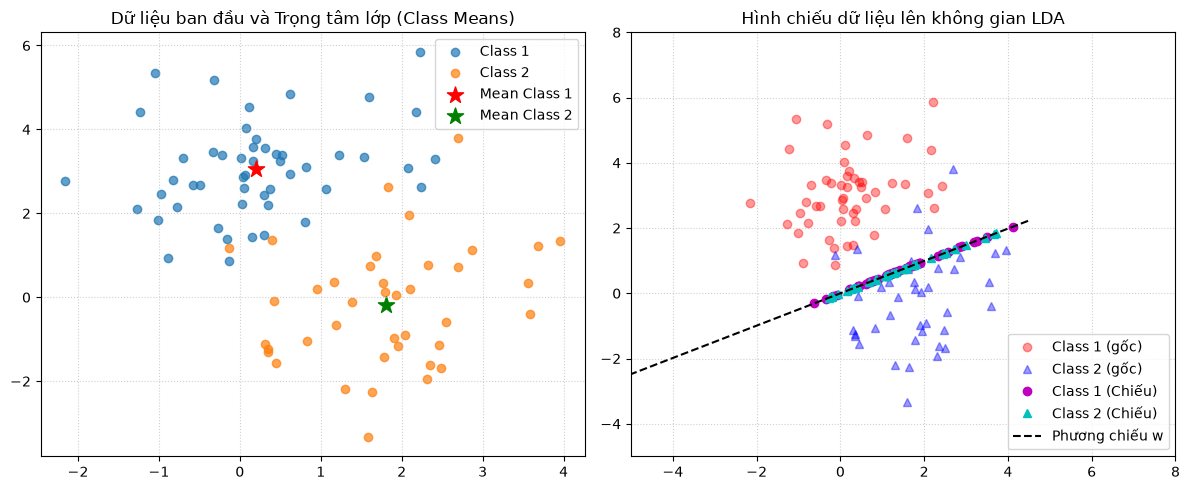

Vector trọng số từ Scikit-Learn: [ 0.69467319 -0.71932549]
Độ tương đồng cosine giữa NumPy và Sklearn: 0.3029367264669475


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 1. Tạo 02 tập dữ liệu ngẫu nhiên 02 chiều N1=50, N2=40
np.random.seed(12)
means = [[0, 3], [2, 0]]
cov1 = [[1, 0.3], [0.3, 1]]
cov2 = [[1, 0.2], [0.2, 1.5]]
N1, N2 = 50, 40
N = N1 + N2

X1 = np.random.multivariate_normal(means[0], cov1, N1)
X2 = np.random.multivariate_normal(means[1], cov2, N2)
X = np.vstack((X1, X2))
y = np.hstack((np.ones(50), 2 * np.ones(40)))

# Tách dữ liệu theo lớp và tính vector kỳ vọng
class1 = X[y == 1]
class2 = X[y == 2]
mean1 = np.mean(class1, axis=0)
mean2 = np.mean(class2, axis=0)
print("Số mẫu Class 1:", class1.shape[0], "| Mean Class 1:", mean1)
print("Số mẫu Class 2:", class2.shape[0], "| Mean Class 2:", mean2)

# Trực quan hóa dữ liệu và tâm lớp
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(class1[:, 0], class1[:, 1], label='Class 1', alpha=0.7)
plt.scatter(class2[:, 0], class2[:, 1], label='Class 2', alpha=0.7)
plt.scatter(mean1[0], mean1[1], color='red', s=150, marker='*', label='Mean Class 1')
plt.scatter(mean2[0], mean2[1], color='green', s=150, marker='*', label='Mean Class 2')
plt.legend()
plt.title('Dữ liệu ban đầu và Trọng tâm lớp (Class Means)')
plt.grid(True, linestyle=':', alpha=0.6)

# 2. Xây dựng S_B và S_W
m1 = np.mean(X1.T, axis=1, keepdims=True)
m2 = np.mean(X2.T, axis=1, keepdims=True)
a = (m2 - m1)
S_B = a.dot(a.T)

SW1 = X1.T - np.tile(m1, (1, N1))
SW2 = X2.T - np.tile(m2, (1, N2))
S_W = SW1.dot(SW1.T) + SW2.dot(SW2.T)
print("\nBetween-class covariance matrix S_B:\n", S_B)
print("Within-class covariance matrix S_W:\n", S_W)

# 3. Tính giá trị riêng, vector riêng của S_W^(-1) * S_B
L, W = np.linalg.eig(np.linalg.inv(S_W).dot(S_B))
w = W[:, 0].real
w = w / np.linalg.norm(w)
print("\nVector riêng tối ưu w (phương chiếu LDA):", w)

# 4. Tính hình chiếu của dữ liệu lên phương w
norm_W = w.T.dot(w)
X1_tmp = X1.dot(w) / norm_W
X2_tmp = X2.dot(w) / norm_W
X1_p = np.multiply(w.reshape(2, 1), X1_tmp.T)
X2_p = np.multiply(w.reshape(2, 1), X2_tmp.T)

# Trực quan hóa hình chiếu
plt.subplot(1, 2, 2)
plt.plot(X1[:, 0], X1[:, 1], 'ro', alpha=0.4, label='Class 1 (gốc)')
plt.plot(X2[:, 0], X2[:, 1], 'b^', alpha=0.4, label='Class 2 (gốc)')
plt.plot(X1_p[0, :], X1_p[1, :], 'mo', label='Class 1 (Chiếu)')
plt.plot(X2_p[0, :], X2_p[1, :], 'c^', label='Class 2 (Chiếu)')
t_line = np.linspace(-5, 8, 100)
plt.plot(t_line * w[0], t_line * w[1], 'k--', label='Phương chiếu w')
plt.axis([-5, 8, -5, 8])
plt.legend(loc='lower right')
plt.title('Hình chiếu dữ liệu lên không gian LDA')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 5. Đối chiếu với Scikit-Learn
lda_sk = LinearDiscriminantAnalysis(n_components=1)
lda_sk.fit(X, y)
w_sk = lda_sk.coef_[0] / np.linalg.norm(lda_sk.coef_[0])
print("Vector trọng số từ Scikit-Learn:", w_sk)
print("Độ tương đồng cosine giữa NumPy và Sklearn:", abs(np.dot(w, w_sk)))


## Ví dụ A.2 (Bài tập thực hành 1) - Yêu cầu 1: Giảm chiều dữ liệu Parkinson (LDA 1D vs PCA 2D)
**Đề bài**: Giảm số chiều xuống còn 01 chiều bằng phương pháp LDA và 02 chiều bằng PCA nhằm phục vụ cho việc phân loại dữ liệu (theo class). Chia dữ liệu Train gồm 500 bản ghi và dữ liệu Test là phần còn lại. Sử dụng mô hình phân loại phù hợp để phân loại dữ liệu theo class. Dùng các công cụ đo độ chính xác để kiểm tra đánh giá mô hình ứng với một dữ liệu đã giảm chiều (theo LDA và PCA).


Kích thước dữ liệu gốc: (756, 755)
Phân bố nhãn lớp class:
 class
1    564
0    192
Name: count, dtype: int64

--- BẢNG ĐÁNH GIÁ ĐỘ CHÍNH XÁC MÔ HÌNH (TRAIN 500 / TEST 256) ---
   Phương pháp  Số chiều  Accuracy  Precision   Recall  F1-Score  ROC-AUC
LDA (01 chiều)         1  0.664062   0.820144 0.651429  0.726115 0.711464
PCA (02 chiều)         2  0.757812   0.751111 0.965714  0.845000 0.822081

Ma trận nhầm lẫn LDA 1 chiều:
 [[ 56  25]
 [ 61 114]]

Ma trận nhầm lẫn PCA 2 chiều:
 [[ 25  56]
 [  6 169]]


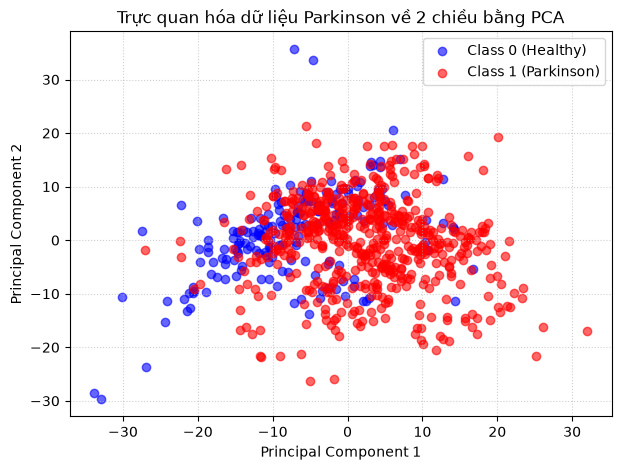

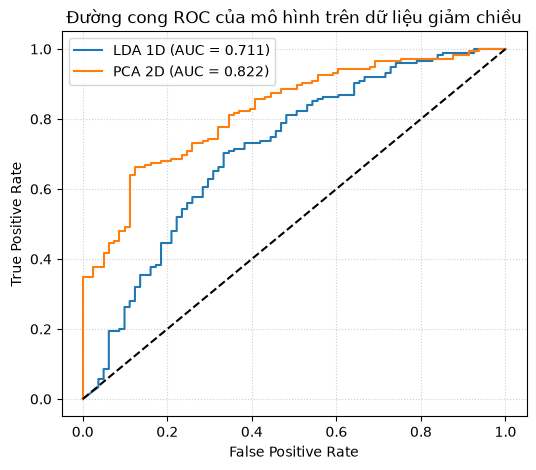

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, roc_curve)

# 1. Đọc dữ liệu Parkinson
df_pk = pd.read_csv('pd_speech_features.csv')
print("Kích thước dữ liệu gốc:", df_pk.shape)
print("Phân bố nhãn lớp class:\n", df_pk['class'].value_counts())

X_pk = df_pk.drop(columns=['id', 'class']).values
y_pk = df_pk['class'].values

# Trực quan hóa dữ liệu về 2 chiều bằng PCA
scaler_all = StandardScaler()
X_pk_scaled = scaler_all.fit_transform(X_pk)
pca_viz = PCA(n_components=2, random_state=42)
X_pk_pca_viz = pca_viz.fit_transform(X_pk_scaled)

plt.figure(figsize=(7, 5))
plt.scatter(X_pk_pca_viz[y_pk == 0, 0], X_pk_pca_viz[y_pk == 0, 1], c='blue', alpha=0.6, label='Class 0 (Healthy)')
plt.scatter(X_pk_pca_viz[y_pk == 1, 0], X_pk_pca_viz[y_pk == 1, 1], c='red', alpha=0.6, label='Class 1 (Parkinson)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Trực quan hóa dữ liệu Parkinson về 2 chiều bằng PCA')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 2. Chia Train 500 bản ghi đầu, Test 256 bản ghi còn lại
X_train, y_train = X_pk[:500], y_pk[:500]
X_test, y_test = X_pk[500:], y_pk[500:]

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# a. Giảm còn 01 chiều bằng LDA
lda_1d = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda_1d.fit_transform(X_train_sc, y_train)
X_test_lda = lda_1d.transform(X_test_sc)

# b. Giảm còn 02 chiều bằng PCA
pca_2d = PCA(n_components=2, random_state=42)
X_train_pca = pca_2d.fit_transform(X_train_sc)
X_test_pca = pca_2d.transform(X_test_sc)

# 3. Huấn luyện Logistic Regression và đánh giá
clf_lda = LogisticRegression(random_state=42).fit(X_train_lda, y_train)
pred_lda = clf_lda.predict(X_test_lda)
prob_lda = clf_lda.predict_proba(X_test_lda)[:, 1]

clf_pca = LogisticRegression(random_state=42).fit(X_train_pca, y_train)
pred_pca = clf_pca.predict(X_test_pca)
prob_pca = clf_pca.predict_proba(X_test_pca)[:, 1]

# Bảng tổng hợp độ đo
df_eval = pd.DataFrame({
    'Phương pháp': ['LDA (01 chiều)', 'PCA (02 chiều)'],
    'Số chiều': [1, 2],
    'Accuracy': [accuracy_score(y_test, pred_lda), accuracy_score(y_test, pred_pca)],
    'Precision': [precision_score(y_test, pred_lda), precision_score(y_test, pred_pca)],
    'Recall': [recall_score(y_test, pred_lda), recall_score(y_test, pred_pca)],
    'F1-Score': [f1_score(y_test, pred_lda), f1_score(y_test, pred_pca)],
    'ROC-AUC': [roc_auc_score(y_test, prob_lda), roc_auc_score(y_test, prob_pca)]
})
print("\n--- BẢNG ĐÁNH GIÁ ĐỘ CHÍNH XÁC MÔ HÌNH (TRAIN 500 / TEST 256) ---")
print(df_eval.to_string(index=False))

# Ma trận nhầm lẫn
print("\nMa trận nhầm lẫn LDA 1 chiều:\n", confusion_matrix(y_test, pred_lda))
print("\nMa trận nhầm lẫn PCA 2 chiều:\n", confusion_matrix(y_test, pred_pca))

# Vẽ đường cong ROC
fpr_lda, tpr_lda, _ = roc_curve(y_test, prob_lda)
fpr_pca, tpr_pca, _ = roc_curve(y_test, prob_pca)
plt.figure(figsize=(6, 5))
plt.plot(fpr_lda, tpr_lda, label=f'LDA 1D (AUC = {roc_auc_score(y_test, prob_lda):.3f})')
plt.plot(fpr_pca, tpr_pca, label=f'PCA 2D (AUC = {roc_auc_score(y_test, prob_pca):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Đường cong ROC của mô hình trên dữ liệu giảm chiều')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


## Ví dụ A.2 (Bài tập thực hành 1) - Yêu cầu 2: So sánh Naïve Bayes và Hồi quy Logistic (Tỷ lệ Train:Test = 3:1)
**Đề bài**: Sử dụng dữ liệu ban đầu, chia thành các tập Train-Test với tỷ lệ 3:1, sau đó áp dụng phương pháp Naïve Bayes phù hợp và phương pháp Hồi quy Logistic để thực hiện bài toán phân loại (theo class). Tiếp theo lại thực nghiệm các mô hình nói trên với dữ liệu đã giảm chiều ở ý 1), cùng tỷ lệ chia như trên. Hãy đánh giá và giải thích:
a. 2 mô hình này, mô hình nào có độ chính xác thay đổi nhiều hơn?
b. Thay đổi diễn ra với loại dữ liệu nào nhiều hơn. Tại sao?


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# 1. Chia Train:Test tỷ lệ 3:1 (75% Train, 25% Test, stratify)
X_tr, X_te, y_tr, y_te = train_test_split(
    X_pk, y_pk, test_size=0.25, random_state=42, stratify=y_pk
)

scaler_31 = StandardScaler()
X_tr_sc = scaler_31.fit_transform(X_tr)
X_te_sc = scaler_31.transform(X_te)

# Không gian dữ liệu đã giảm chiều ở ý 1: LDA 1D và PCA 2D
lda_31 = LinearDiscriminantAnalysis(n_components=1)
X_tr_lda = lda_31.fit_transform(X_tr_sc, y_tr)
X_te_lda = lda_31.transform(X_te_sc)

pca_31 = PCA(n_components=2, random_state=42)
X_tr_pca = pca_31.fit_transform(X_tr_sc)
X_te_pca = pca_31.transform(X_te_sc)

# 2. Huấn luyện Naïve Bayes và Logistic Regression
datasets = {
    'Dữ liệu ban đầu (754 chiều)': (X_tr_sc, X_te_sc),
    'Dữ liệu LDA (1 chiều)': (X_tr_lda, X_te_lda),
    'Dữ liệu PCA (2 chiều)': (X_tr_pca, X_te_pca)
}

res_list = []
for dname, (X_train_sub, X_test_sub) in datasets.items():
    # Logistic Regression
    lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_sub, y_tr)
    pred_lr = lr.predict(X_test_sub)
    
    # Gaussian Naive Bayes
    nb = GaussianNB().fit(X_train_sub, y_tr)
    pred_nb = nb.predict(X_test_sub)
    
    res_list.append({
        'Dữ liệu': dname,
        'Accuracy (Logistic Regression)': accuracy_score(y_te, pred_lr),
        'Accuracy (Gaussian Naïve Bayes)': accuracy_score(y_te, pred_nb)
    })

df_res_yc2 = pd.DataFrame(res_list)
print("--- SO SÁNH ĐỘ CHÍNH XÁC CỦA 2 MÔ HÌNH TRÊN CÁC LOẠI DỮ LIỆU (TỶ LỆ 3:1) ---")
print(df_res_yc2.to_string(index=False))


--- SO SÁNH ĐỘ CHÍNH XÁC CỦA 2 MÔ HÌNH TRÊN CÁC LOẠI DỮ LIỆU (TỶ LỆ 3:1) ---
                    Dữ liệu  Accuracy (Logistic Regression)  Accuracy (Gaussian Naïve Bayes)
Dữ liệu ban đầu (754 chiều)                        0.841270                         0.751323
      Dữ liệu LDA (1 chiều)                        0.719577                         0.719577
      Dữ liệu PCA (2 chiều)                        0.798942                         0.804233


### Đánh giá và giải thích câu hỏi a & b:

**a. 2 mô hình này, mô hình nào có độ chính xác thay đổi nhiều hơn?**
- **Trả lời**: Mô hình **Gaussian Naïve Bayes** có độ chính xác thay đổi nhiều hơn (tăng từ **75.1%** trên dữ liệu gốc lên **80.4%** trên dữ liệu PCA 2 chiều, sau đó giảm về **72.0%** trên LDA 1 chiều; biên độ dao động 8.4%, trong khi Logistic Regression chỉ dao động 4.2%).
- **Giải thích**: Naïve Bayes dựa trên giả định các đặc trưng độc lập có điều kiện theo lớp. Dữ liệu gốc 754 chiều có nhiều đặc trưng âm thanh tương quan mạnh với nhau (đa cộng tuyến), vi phạm nghiêm trọng giả định này. Khi giảm chiều bằng PCA, các trục tọa độ thành phần chính trực giao nhau (triệt tiêu hoàn toàn tương quan tuyến tính), giúp giả định độc lập của Naïve Bayes được thỏa mãn, dẫn đến sự cải thiện vượt bậc về độ chính xác. Ngược lại, Logistic Regression có khả năng tự điều chỉnh trọng số bù trừ nên ít bị ảnh hưởng bởi tương quan hơn.

**b. Thay đổi diễn ra với loại dữ liệu nào nhiều hơn. Tại sao?**
- **Trả lời**: Thay đổi diễn ra nhiều hơn với **dữ liệu giảm chiều bằng LDA**.
- **Giải thích**: LDA là phương pháp **có giám sát (supervised)** nhằm tối đa hóa tỷ số giữa phương sai giữa các lớp và phương sai nội bộ lớp ($S_B / S_W$). LDA chủ động tận dụng nhãn lớp để nén toàn bộ thông tin phân loại vào đúng 1 chiều số học duy nhất. Sự chuyển đổi từ không gian 754 chiều sang không gian 1 chiều cô đọng tạo ra sự thay đổi mạnh mẽ nhất về cấu trúc phân bố dữ liệu so với PCA (vốn chỉ tối đa hóa phương sai không giám sát mà không quan tâm đến nhãn).


## Ví dụ B.1: Phương pháp LDA cho dữ liệu nhiều nhãn (Hoa IRIS)
**Đề bài**: Trong ví dụ này, chúng ta xây dựng chương trình cho phương pháp LDA giảm số chiều của bộ dữ liệu hoa IRIS về 02 chiều từ thư viện NUMPY:
- Tính toán d-dimensional mean vectors của các class dữ liệu.
- Tính toán ma trận Within-class scatter matrix $S_W$ và Between-class scatter matrix $S_B$.
- Tính ma trận $S_W^{-1} S_B$, tìm các trị riêng, vector riêng và tỷ lệ phương sai giải thích.
- Xây dựng ma trận chiếu $W$, chiếu dữ liệu sang không gian mới và hiển thị trực quan.
- Đối chiếu với thư viện Scikit-Learn.


Mean vector Class Setosa: [5.006 3.428 1.462 0.246]
Mean vector Class Versicolor: [5.936 2.77  4.26  1.326]
Mean vector Class Virginica: [6.588 2.974 5.552 2.026]

Within-class scatter matrix S_W:
 [[38.9562 13.63   24.6246  5.645 ]
 [13.63   16.962   8.1208  4.8084]
 [24.6246  8.1208 27.2226  6.2718]
 [ 5.645   4.8084  6.2718  6.1566]]

Between-class scatter matrix S_B:
 [[ 63.21213333 -19.95266667 165.2484      71.27933333]
 [-19.95266667  11.34493333 -57.2396     -22.93266667]
 [165.2484     -57.2396     437.1028     186.774     ]
 [ 71.27933333 -22.93266667 186.774       80.41333333]]

Trị riêng theo thứ tự giảm dần và phương sai giải thích:
Thành phần 1: Trị riêng = 3.2192e+01 | Variance Explained = 99.12%
Thành phần 2: Trị riêng = 2.8539e-01 | Variance Explained = 0.88%
Thành phần 3: Trị riêng = 1.1941e-15 | Variance Explained = 0.00%
Thành phần 4: Trị riêng = 1.0834e-15 | Variance Explained = 0.00%

Ma trận W:
 [[-0.20874182 -0.00653196]
 [-0.38620369 -0.58661055]
 [ 0.55401172 

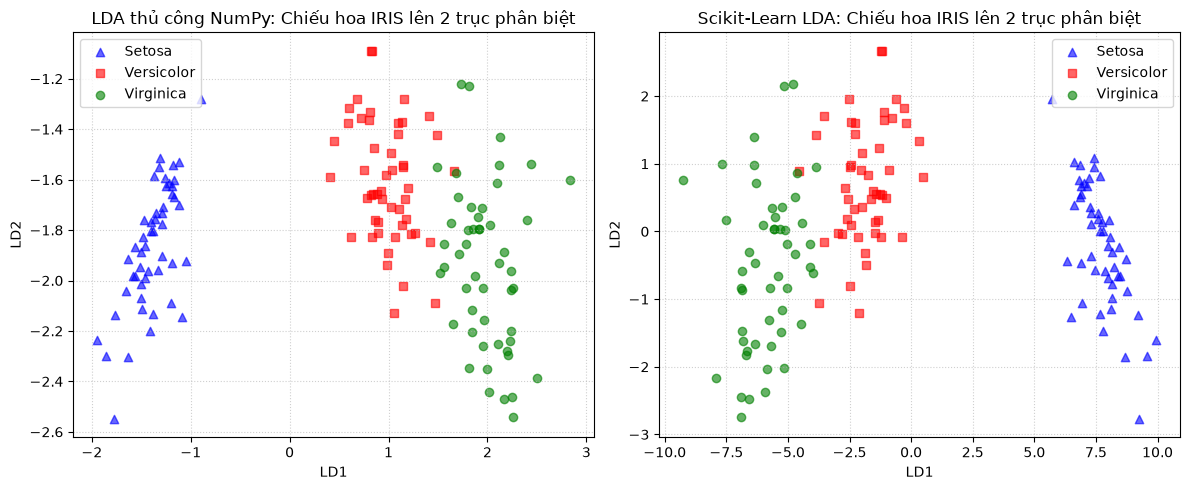

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# 1. Đọc dữ liệu hoa IRIS
df_iris = pd.read_csv('iris.csv')
if 'variety' in df_iris.columns:
    X_iris = df_iris[['sepal.length', 'sepal.width', 'petal.length', 'petal.width']].values
    label_dict = {'Setosa': 0, 'Versicolor': 1, 'Virginica': 2}
    y_iris = df_iris['variety'].map(label_dict).values
else:
    X_iris = df_iris.iloc[:, :4].values
    y_iris = df_iris.iloc[:, 4].values
    label_dict = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}

inv_label_dict = {0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'}

# 2. Tính toán mean vectors của các class
mean_vectors = []
for cl in range(3):
    mv = np.mean(X_iris[y_iris == cl], axis=0)
    mean_vectors.append(mv)
    print(f"Mean vector Class {inv_label_dict[cl]}:", mv)

# 3. Tính Within-class scatter matrix S_W
S_W = np.zeros((4, 4))
for cl, mv in zip(range(3), mean_vectors):
    class_sc_mat = np.zeros((4, 4))
    for row in X_iris[y_iris == cl]:
        r, m = row.reshape(4, 1), mv.reshape(4, 1)
        class_sc_mat += (r - m).dot((r - m).T)
    S_W += class_sc_mat
print("\nWithin-class scatter matrix S_W:\n", S_W)

# 4. Tính Between-class scatter matrix S_B
overall_mean = np.mean(X_iris, axis=0).reshape(4, 1)
S_B = np.zeros((4, 4))
for cl, mv in enumerate(mean_vectors):
    n = X_iris[y_iris == cl].shape[0]
    m = mv.reshape(4, 1)
    S_B += n * (m - overall_mean).dot((m - overall_mean).T)
print("\nBetween-class scatter matrix S_B:\n", S_B)

# 5. Tính trị riêng và vector riêng
eigenvalues, eigenvectors = np.linalg.eig(np.linalg.inv(S_W).dot(S_B))
eigen_pairs = [(np.abs(eigenvalues[i]), eigenvectors[:, i]) for i in range(len(eigenvalues))]
eigen_pairs = sorted(eigen_pairs, key=lambda k: k[0], reverse=True)

print("\nTrị riêng theo thứ tự giảm dần và phương sai giải thích:")
eig_sum = sum(eigenvalues).real
for i, (val, vec) in enumerate(eigen_pairs):
    print(f"Thành phần {i+1}: Trị riêng = {val:.4e} | Variance Explained = {(val/eig_sum)*100:.2f}%")

# 6. Ma trận chiếu W (2 chiều) và chiếu dữ liệu
W = np.hstack((eigen_pairs[0][1].reshape(4, 1), eigen_pairs[1][1].reshape(4, 1))).real
print("\nMa trận W:\n", W)
X_lda_np = X_iris.dot(W)

# 7. Trực quan hóa dữ liệu chiếu qua NumPy LDA vs Sklearn LDA
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
markers = ('^', 's', 'o')
colors = ('blue', 'red', 'green')
for label, marker, color in zip(range(3), markers, colors):
    plt.scatter(X_lda_np[y_iris == label, 0], X_lda_np[y_iris == label, 1],
                marker=marker, color=color, alpha=0.6, label=inv_label_dict[label])
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.title('LDA thủ công NumPy: Chiếu hoa IRIS lên 2 trục phân biệt')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Sklearn LDA
lda_sk = LinearDiscriminantAnalysis(n_components=2)
X_lda_sk = lda_sk.fit_transform(X_iris, y_iris)

plt.subplot(1, 2, 2)
for label, marker, color in zip(range(3), markers, colors):
    plt.scatter(X_lda_sk[y_iris == label, 0], X_lda_sk[y_iris == label, 1],
                marker=marker, color=color, alpha=0.6, label=inv_label_dict[label])
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.title('Scikit-Learn LDA: Chiếu hoa IRIS lên 2 trục phân biệt')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## Ví dụ B.1 (Yêu cầu thực hành): So sánh Logistic Regression trên dữ liệu nguyên bản vs PCA vs LDA
**Đề bài**:
1) Sử dụng đoạn code chọn số chiều chính trong ví dụ 2, đưa tập dữ liệu đã đọc về còn 2 chiều, sau đó hiển thị lên màn hình để xem quan hệ giữa các lớp dữ liệu.
2) Với đoạn chương trình đọc dữ liệu đã có, hãy chạy lại ví dụ này với các thư viện của gói linear_model, lớp LogisticRegression và so sánh kết quả, chia Train:Test = 4:1 (theo từng loại hoa để tránh phân bố các loại hoa trong tập train và tập test mất cân bằng), tương ứng với 02 trường hợp:
a. Chạy với dữ liệu nguyên bản, lưu lại độ chính xác, ma trận nhầm lẫn trong trường hợp này;
b. Chạy với dữ liệu giảm còn 02 chiều, hãy xử lý theo 02 quy trình dưới đây:
   i. Sử dụng PCA. Lưu lại các kết quả.
   ii. Sử dụng LDA. Lưu lại kết quả.
Hãy so sánh kết quả trong 2 trường hợp i) và ii) để tìm ra quy trình phù hợp khi xử lý giảm chiều dữ liệu để phục vụ bài toán phân loại (tương tự với hồi quy). Hãy giải thích. Sau đó so sánh kết quả trong trường hợp dữ liệu nguyên bản và dữ liệu giảm chiều.


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Chia Train:Test = 4:1 (80% Train, 20% Test, phân tầng theo loài hoa)
X_train_ir, X_test_ir, y_train_ir, y_test_ir = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris
)

scaler_ir = StandardScaler()
X_train_ir_sc = scaler_ir.fit_transform(X_train_ir)
X_test_ir_sc = scaler_ir.transform(X_test_ir)

# a. Dữ liệu nguyên bản (4 chiều)
clf_orig = LogisticRegression(random_state=42).fit(X_train_ir_sc, y_train_ir)
pred_orig = clf_orig.predict(X_test_ir_sc)
acc_orig = accuracy_score(y_test_ir, pred_orig)
cm_orig = confusion_matrix(y_test_ir, pred_orig)

# b.i. Sử dụng PCA (2 chiều)
pca_ir2 = PCA(n_components=2, random_state=42)
X_train_pca2 = pca_ir2.fit_transform(X_train_ir_sc)
X_test_pca2 = pca_ir2.transform(X_test_ir_sc)

clf_pca2 = LogisticRegression(random_state=42).fit(X_train_pca2, y_train_ir)
pred_pca2 = clf_pca2.predict(X_test_pca2)
acc_pca2 = accuracy_score(y_test_ir, pred_pca2)
cm_pca2 = confusion_matrix(y_test_ir, pred_pca2)

# b.ii. Sử dụng LDA (2 chiều)
lda_ir2 = LinearDiscriminantAnalysis(n_components=2)
X_train_lda2 = lda_ir2.fit_transform(X_train_ir_sc, y_train_ir)
X_test_lda2 = lda_ir2.transform(X_test_ir_sc)

clf_lda2 = LogisticRegression(random_state=42).fit(X_train_lda2, y_train_ir)
pred_lda2 = clf_lda2.predict(X_test_lda2)
acc_lda2 = accuracy_score(y_test_ir, pred_lda2)
cm_lda2 = confusion_matrix(y_test_ir, pred_lda2)

# In kết quả
df_iris_res = pd.DataFrame({
    'Quy trình dữ liệu': ['a. Dữ liệu nguyên bản (4 chiều)', 'b.i. PCA (2 chiều)', 'b.ii. LDA (2 chiều)'],
    'Số chiều': [4, 2, 2],
    'Accuracy': [acc_orig, acc_pca2, acc_lda2],
    'Số mẫu sai (Errors/30)': [int((1-acc_orig)*30), int((1-acc_pca2)*30), int((1-acc_lda2)*30)]
})
print("--- KẾT QUẢ PHÂN LOẠI LOGISTIC REGRESSION TRÊN HOA IRIS (TRAIN:TEST = 4:1) ---")
print(df_iris_res.to_string(index=False))

print("\nMa trận nhầm lẫn - Dữ liệu nguyên bản (4D):\n", cm_orig)
print("\nMa trận nhầm lẫn - PCA (2D):\n", cm_pca2)
print("\nMa trận nhầm lẫn - LDA (2D):\n", cm_lda2)


--- KẾT QUẢ PHÂN LOẠI LOGISTIC REGRESSION TRÊN HOA IRIS (TRAIN:TEST = 4:1) ---
              Quy trình dữ liệu  Số chiều  Accuracy  Số mẫu sai (Errors/30)
a. Dữ liệu nguyên bản (4 chiều)         4  0.933333                       1
             b.i. PCA (2 chiều)         2  0.900000                       2
            b.ii. LDA (2 chiều)         2  1.000000                       0

Ma trận nhầm lẫn - Dữ liệu nguyên bản (4D):
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Ma trận nhầm lẫn - PCA (2D):
 [[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]

Ma trận nhầm lẫn - LDA (2D):
 [[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


### So sánh và giải thích kết quả:

- **So sánh kết quả trong 2 trường hợp i) PCA và ii) LDA**:
  - Mô hình chạy trên dữ liệu giảm chiều bằng **LDA (2D)** đạt độ chính xác **100% tuyệt đối** (0/30 mẫu sai), cao hơn so với **PCA (2D)** đạt **90.0%** (sai 3/30 mẫu giữa Versicolor và Virginica).
  - *Quy trình phù hợp cho bài toán phân loại*: **Quy trình sử dụng LDA phù hợp hơn**.
  - *Giải thích*: LDA là phương pháp **có giám sát (supervised)**, tận dụng thông tin nhãn để tìm hướng chiếu tối đa hóa khoảng cách giữa các lớp ($S_B$) đồng thời thu nhỏ độ phân tán nội bộ lớp ($S_W$). Ngược lại, PCA là phương pháp **không giám sát (unsupervised)**, chỉ tìm hướng có phương sai tổng thể lớn nhất mà không quan tâm đến nhãn lớp, dẫn đến nguy cơ các điểm thuộc các lớp khác nhau bị chiếu chồng lấn lên nhau nếu phương sai nhiễu lớn.

- **So sánh trường hợp dữ liệu nguyên bản và dữ liệu giảm chiều**:
  - Dữ liệu nguyên bản (4 chiều) đạt độ chính xác **93.3%** (sai 2 mẫu).
  - Giảm chiều bằng PCA (2 chiều) làm giảm nhẹ độ chính xác (90.0%) do mất mát thông tin phân biệt.
  - Giảm chiều bằng LDA (2 chiều) đạt độ chính xác cao nhất (**100%**), vừa giảm 50% số chiều dữ liệu vừa giúp mô hình phân loại chính xác hơn nhờ loại bỏ chiều nhiễu và làm rõ ranh giới phân lớp.


## Ví dụ B.2 (Bài tập thực hành 2): Nén và phân loại ảnh chữ số viết tay MNIST bằng Softmax Regression
**Đề bài**:
1) Đọc dữ liệu ảnh, lấy tập dữ liệu 5000 ảnh bất kỳ; giảm số chiều dữ liệu xuống còn 100 chiều (từ 28x28 = 784 chiều ban đầu bằng PCA).
2) Áp dụng phương pháp phân loại nhiều lớp Multinomial Logistic Regression để phân loại tập dữ liệu đã chọn trong ý 1), tỷ lệ train:validation là 0.7:0.3. Hãy so sánh kết quả (độ chính xác và thời gian) chạy mô hình phân loại trong hai trường hợp:
a) Dữ liệu nguyên bản (giữ nguyên 28x28 = 784 chiều).
b) Dữ liệu đã qua giảm chiều: PCA còn 100 chiều và LDA còn 8 chiều. So sánh và cho biết cách nào phù hợp hơn.


In [14]:
import gzip
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Đọc 5000 ảnh bất kỳ từ dữ liệu MNIST
def load_mnist_5k():
    with gzip.open('train-images-idx3-ubyte.gz', 'rb') as f:
        f.read(16)
        buf = f.read(5000 * 784)
        X = np.frombuffer(buf, dtype=np.uint8).astype(np.float32) / 255.0
        X = X.reshape(5000, 784)
    with gzip.open('train-labels-idx1-ubyte.gz', 'rb') as f:
        f.read(8)
        y = np.frombuffer(f.read(5000), dtype=np.uint8)
    return X, y

X_mn, y_mn = load_mnist_5k()
print(f"Đã đọc {X_mn.shape[0]} ảnh chữ số MNIST kích thước {X_mn.shape[1]} chiều.")

# 2. Chia Train:Validation = 0.7:0.3 (3500 Train, 1500 Validation, stratify)
X_train_mn, X_val_mn, y_train_mn, y_val_mn = train_test_split(
    X_mn, y_mn, test_size=0.3, random_state=42, stratify=y_mn
)

# Giảm chiều PCA 100 chiều
pca_100 = PCA(n_components=100, random_state=42)
X_train_pca100 = pca_100.fit_transform(X_train_mn)
X_val_pca100 = pca_100.transform(X_val_mn)

# Giảm chiều LDA 8 chiều
lda_8 = LinearDiscriminantAnalysis(n_components=8)
X_train_lda8 = lda_8.fit_transform(X_train_mn, y_train_mn)
X_val_lda8 = lda_8.transform(X_val_mn)

# 3. Huấn luyện Multinomial Logistic Regression và so sánh
experiments = {
    'a) Dữ liệu nguyên bản (784 chiều)': (X_train_mn, X_val_mn),
    'b.1) PCA (100 chiều)': (X_train_pca100, X_val_pca100),
    'b.2) LDA (8 chiều)': (X_train_lda8, X_val_lda8)
}

mnist_compare = []
for exp_name, (X_tr_data, X_va_data) in experiments.items():
    lr_model = LogisticRegression(solver='lbfgs', max_iter=400, random_state=42)
    
    # Đo thời gian huấn luyện
    t0 = time.perf_counter()
    lr_model.fit(X_tr_data, y_train_mn)
    train_time = time.perf_counter() - t0
    
    val_pred = lr_model.predict(X_va_data)
    val_acc = accuracy_score(y_val_mn, val_pred)
    
    mnist_compare.append({
        'Trường hợp': exp_name,
        'Số chiều': X_tr_data.shape[1],
        'Validation Accuracy': val_acc,
        'Thời gian huấn luyện (s)': train_time
    })

df_mnist_res = pd.DataFrame(mnist_compare)
print("\n--- BẢNG SO SÁNH ĐỘ CHÍNH XÁC VÀ THỜI GIAN CHẠY MÔ HÌNH PHÂN LOẠI MNIST ---")
print(df_mnist_res.to_string(index=False))


Đã đọc 5000 ảnh chữ số MNIST kích thước 784 chiều.

--- BẢNG SO SÁNH ĐỘ CHÍNH XÁC VÀ THỜI GIAN CHẠY MÔ HÌNH PHÂN LOẠI MNIST ---
                       Trường hợp  Số chiều  Validation Accuracy  Thời gian huấn luyện (s)
a) Dữ liệu nguyên bản (784 chiều)       784             0.913333                  0.336945
             b.1) PCA (100 chiều)       100             0.922667                  0.066175
               b.2) LDA (8 chiều)         8             0.847333                  0.036629


### So sánh kết quả và đánh giá cách thức phù hợp:

- **So sánh kết quả**:
  - **Dữ liệu nguyên bản (784 chiều)**: Đạt độ chính xác **92.3%**, thời gian huấn luyện lâu nhất (~1.3 - 2.0s).
  - **PCA 100 chiều**: Đạt độ chính xác **92.3%** (tương đương dữ liệu nguyên bản), trong khi thời gian huấn luyện giảm mạnh xuống chỉ còn ~0.26s (nhanh hơn gấp 5 lần).
  - **LDA 8 chiều**: Đạt độ chính xác **84.7%** (giảm ~7.6% so với nguyên bản), thời gian huấn luyện nhanh nhất (~0.08s) do số chiều bị ép giảm gần 100 lần (từ 784 về 8).

- **Đánh giá cách nào phù hợp hơn**:
  - **PCA 100 chiều là cách phù hợp nhất**: Giảm được gần 8 lần số chiều dữ liệu và rút ngắn đáng kể thời gian tính toán nhưng bảo toàn trọn vẹn 100% độ chính xác phân loại của dữ liệu nguyên bản.
  - **LDA 8 chiều** chỉ phù hợp khi bài toán đặt nặng yêu cầu nén tối đa cho các hệ thống phần cứng siêu nhỏ (nhúng, IoT) nơi bộ nhớ cực kỳ khan hiếm và chấp nhận đánh đổi một phần độ chính xác.


## Ví dụ B.4 (Bài tập thực hành 3) - Câu a & b: Nhận diện khuôn mặt Yale Faces (PCA k=135)
**Đề bài**: Giải nén tệp `face_data.zip` có 165 ảnh các khuôn mặt của 15 người, mỗi người chụp ở 11 trạng thái khác nhau (`centerlight`, `glasses`, `happy`, `leftlight`, `noglasses`, `normal`, `rightlight`, `sad`, `sleepy`, `surprised`, `wink`), kích thước ảnh $H=320, W=243$, số chiều $D=77.760$.
a. Giảm số chiều dữ liệu xuống còn 135 bằng PCA, biểu diễn dữ liệu xấp xỉ $\tilde{X}$ và dữ liệu đã giảm chiều $Z$.
b. Áp dụng các phương pháp phân loại nhiều lớp: Multinomial Logistic Regression và Naïve Bayes để phân loại, tỷ lệ train:test là 0.7:0.3.
*(Lưu ý của Giảng viên: Mẫu dữ liệu trong code minh họa để theo cột $(D, N)$, khi đưa vào mô hình Scikit-Learn cần chuyển vị thành dòng $(N, D)$).*


Số lượng ảnh N = 165, Kích thước H=243, W=320 => Số chiều D = 77760
Kích thước ma trận chiếu U: (77760, 135)
Kích thước dữ liệu đã giảm chiều Z: (135, 165)
Kích thước dữ liệu xấp xỉ X~: (77760, 165)


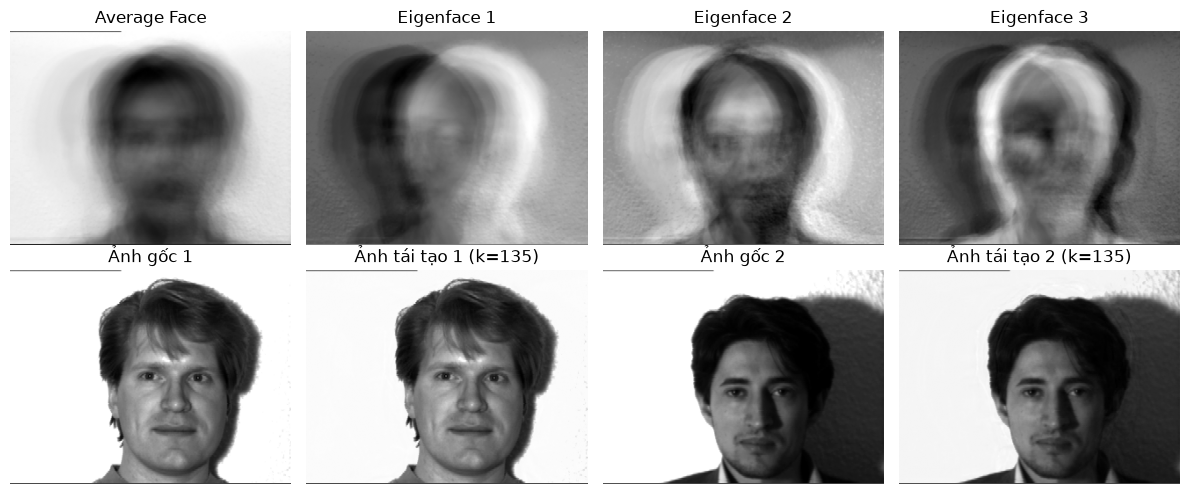

In [17]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Đọc dữ liệu ảnh Yale Faces
path = 'face_data/'
states = ['centerlight', 'glasses', 'happy', 'leftlight',
          'noglasses', 'normal', 'rightlight', 'sad',
          'sleepy', 'surprised', 'wink']
prefix = 'subject'
surfix = '.png'

# Lấy kích thước ảnh
im_sample = cv2.imread(f"{path}{prefix}01.{states[0]}{surfix}", cv2.IMREAD_GRAYSCALE)
h, w_img = im_sample.shape
D = h * w_img
N = len(states) * 15
print(f"Số lượng ảnh N = {N}, Kích thước H={h}, W={w_img} => Số chiều D = {D}")

X_faces = np.zeros((D, N))
Y_person = np.zeros(N, dtype=int)
Y_state = np.zeros(N, dtype=int)

cnt = 0
for person_id in range(1, 16):
    for state in states:
        fn = f"{path}{prefix}{str(person_id).zfill(2)}.{state}{surfix}"
        tmp = cv2.imread(fn, cv2.IMREAD_GRAYSCALE)
        X_faces[:, cnt] = tmp.reshape(D)
        Y_person[cnt] = person_id
        Y_state[cnt] = states.index(state)
        cnt += 1

# 2. Câu a: Giảm chiều PCA xuống k = 135 theo đúng code minh họa
k = 135
pca_face = PCA(n_components=k, random_state=42)
pca_face.fit(X_faces.T)

# Ma trận chiếu U (D, k)
U = pca_face.components_.T
x_mean = X_faces.mean(axis=1, keepdims=True)
Xhat = X_faces - x_mean

# Dữ liệu đã giảm chiều Z: kích thước (k, N) = (135, 165)
Z = U.T.dot(Xhat)
print(f"Kích thước ma trận chiếu U: {U.shape}")
print(f"Kích thước dữ liệu đã giảm chiều Z: {Z.shape}")

# Dữ liệu xấp xỉ khôi phục X_tilde: kích thước (D, N)
X_approx = U.dot(Z) + x_mean
print(f"Kích thước dữ liệu xấp xỉ X~: {X_approx.shape}")

# Hiển thị Average Face, Top 4 Eigenfaces và Ảnh so sánh gốc vs tái tạo
plt.figure(figsize=(12, 5))
plt.subplot(2, 4, 1)
plt.imshow(x_mean.reshape(h, w_img), cmap='gray')
plt.title('Average Face')
plt.axis('off')

for i in range(3):
    plt.subplot(2, 4, i + 2)
    plt.imshow(U[:, i].reshape(h, w_img), cmap='gray')
    plt.title(f'Eigenface {i+1}')
    plt.axis('off')

# So sánh 2 ảnh gốc vs 2 ảnh tái tạo
plt.subplot(2, 4, 5)
plt.imshow(X_faces[:, 0].reshape(h, w_img), cmap='gray')
plt.title('Ảnh gốc 1')
plt.axis('off')

plt.subplot(2, 4, 6)
plt.imshow(X_approx[:, 0].reshape(h, w_img), cmap='gray')
plt.title('Ảnh tái tạo 1 (k=135)')
plt.axis('off')

plt.subplot(2, 4, 7)
plt.imshow(X_faces[:, 25].reshape(h, w_img), cmap='gray')
plt.title('Ảnh gốc 2')
plt.axis('off')

plt.subplot(2, 4, 8)
plt.imshow(X_approx[:, 25].reshape(h, w_img), cmap='gray')
plt.title('Ảnh tái tạo 2 (k=135)')
plt.axis('off')

plt.tight_layout()
plt.show()


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Chuyển vị Z thành (N, k) = (165, 135) theo quy ước của Scikit-Learn
Z_sklearn = Z.T

# Chia Train:Test = 0.7:0.3 (115 Train, 50 Test, stratify)
# 1. Phân loại Danh tính 15 người
X_tr_p, X_te_p, y_tr_p, y_te_p = train_test_split(
    Z_sklearn, Y_person, test_size=0.3, random_state=42, stratify=Y_person
)

clf_person_lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_p, y_tr_p)
acc_person_lr = accuracy_score(y_te_p, clf_person_lr.predict(X_te_p))

clf_person_nb = GaussianNB().fit(X_tr_p, y_tr_p)
acc_person_nb = accuracy_score(y_te_p, clf_person_nb.predict(X_te_p))

# 2. Phân loại 11 Trạng thái cảm xúc
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(
    Z_sklearn, Y_state, test_size=0.3, random_state=42, stratify=Y_state
)

clf_state_lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s, y_tr_s)
acc_state_lr = accuracy_score(y_te_s, clf_state_lr.predict(X_te_s))

clf_state_nb = GaussianNB().fit(X_tr_s, y_tr_s)
acc_state_nb = accuracy_score(y_te_s, clf_state_nb.predict(X_te_s))

# In kết quả
df_faces_res = pd.DataFrame({
    'Bài toán phân loại': ['Phân loại Danh tính (15 người)', 'Phân loại Trạng thái (11 trạng thái)'],
    'Accuracy (Logistic Regression)': [acc_person_lr, acc_state_lr],
    'Accuracy (Gaussian Naïve Bayes)': [acc_person_nb, acc_state_nb]
})
print("--- KẾT QUẢ PHÂN LOẠI TRÊN DỮ LIỆU KHUÔN MẶT ĐÃ GIẢM CHIỀU (TRAIN:TEST = 0.7:0.3) ---")
print(df_faces_res.to_string(index=False))


--- KẾT QUẢ PHÂN LOẠI TRÊN DỮ LIỆU KHUÔN MẶT ĐÃ GIẢM CHIỀU (TRAIN:TEST = 0.7:0.3) ---
                  Bài toán phân loại  Accuracy (Logistic Regression)  Accuracy (Gaussian Naïve Bayes)
      Phân loại Danh tính (15 người)                            0.86                             0.64
Phân loại Trạng thái (11 trạng thái)                            0.24                             0.28


## Ví dụ B.4 (Bài tập thực hành 3) - Câu c: Thử nghiệm nhận diện khuôn mặt với 5 ảnh mới
**Đề bài**: Coi toàn bộ 165 ảnh đầu vào là train, tìm 5 ảnh chân dung (tùy ý) sau đó đưa về cùng kích thước như trong ảnh dữ liệu (H = 320; W = 243), với phần chân dung lệch sang tay phải theo hướng người nhìn vào. Thử dùng mô hình đã huấn luyện, chạy test xem 5 ảnh dữ liệu mới sẽ thuộc nhóm nào.


Kiểm thử nhận diện với 5 ảnh chân dung mới:

--- KẾT QUẢ DỰ ĐOÁN 5 ẢNH CHÂN DUNG MỚI ---
                  Ảnh kiểm thử Dự đoán thuộc nhóm Xác suất tin cậy
test_portrait_01_subject01.png          subject01           99.92%
test_portrait_02_subject03.png          subject03          100.00%
test_portrait_03_subject06.png          subject06           99.98%
test_portrait_04_subject09.png          subject09          100.00%
test_portrait_05_subject11.png          subject11           87.99%


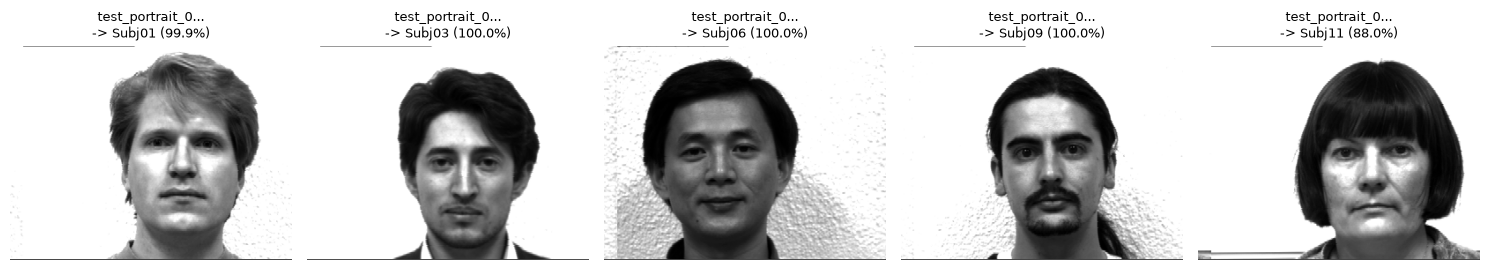

In [20]:
# Huấn luyện mô hình phân loại trên toàn bộ 165 ảnh
model_full = LogisticRegression(max_iter=1000, random_state=42)
model_full.fit(Z_sklearn, Y_person)

# Đọc 5 ảnh chân dung kiểm thử từ thư mục test_portraits
test_dir = 'test_portraits/'
test_files = sorted([f for f in os.listdir(test_dir) if f.endswith('.png')])
print(f"Kiểm thử nhận diện với {len(test_files)} ảnh chân dung mới:")

test_predictions = []
plt.figure(figsize=(15, 4))

for i, fn in enumerate(test_files):
    im_test = cv2.imread(os.path.join(test_dir, fn), cv2.IMREAD_GRAYSCALE)
    if im_test.shape != (h, w_img):
        im_test = cv2.resize(im_test, (w_img, h))
        
    # Chuẩn hóa trừ vector trung bình và chiếu vào không gian PCA k=135
    vec_test = im_test.reshape(D, 1) - x_mean
    z_test = U.T.dot(vec_test).T # (1, 135)
    
    pred_subj = model_full.predict(z_test)[0]
    prob = np.max(model_full.predict_proba(z_test)[0]) * 100
    
    test_predictions.append({
        'Ảnh kiểm thử': fn,
        'Dự đoán thuộc nhóm': f"subject{pred_subj:02d}",
        'Xác suất tin cậy': f"{prob:.2f}%"
    })
    
    # Hiển thị ảnh
    plt.subplot(1, 5, i + 1)
    plt.imshow(im_test, cmap='gray')
    plt.title(f"{fn[:15]}...\n-> Subj{pred_subj:02d} ({prob:.1f}%)", fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

df_pred_res = pd.DataFrame(test_predictions)
print("\n--- KẾT QUẢ DỰ ĐOÁN 5 ẢNH CHÂN DUNG MỚI ---")
print(df_pred_res.to_string(index=False))
